In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense,Dropout, BatchNormalization
from tensorflow.keras.models import Sequential


I0000 00:00:1793947339.559146   66982 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793947340.341880   66982 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793947344.785683   66982 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import tensorflow as tf

# 1. 시스템에 CUDA 빌드가 포함되어 있는지 확인
print("1. CUDA 빌드 여부:", tf.test.is_built_with_cuda())

# 2. 시스템 환경 변수 및 드라이버 오류 메시지 출력 유도
print("2. GPU 장치 이름:", tf.test.gpu_device_name())



1. CUDA 빌드 여부: True
2. GPU 장치 이름: /device:GPU:0


I0000 00:00:1793947350.375656   66982 gpu_device.cc:2043] Created device /device:GPU:0 with 4073 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [3]:
luckey_csv = './lotto_1_to_1246.csv'

In [4]:
luckey = pd.read_csv(luckey_csv)

In [5]:
raw_data = luckey[['번호1', '번호2', '번호3', '번호4', '번호5', '번호6']].values.tolist()

In [8]:
raw_data

[[10, 23, 29, 33, 37, 40],
 [9, 13, 21, 25, 32, 42],
 [11, 16, 19, 21, 27, 31],
 [14, 27, 30, 31, 40, 42],
 [16, 24, 29, 40, 41, 42],
 [14, 15, 26, 27, 40, 42],
 [2, 9, 16, 25, 26, 40],
 [8, 19, 25, 34, 37, 39],
 [2, 4, 16, 17, 36, 39],
 [9, 25, 30, 33, 41, 44],
 [1, 7, 36, 37, 41, 42],
 [2, 11, 21, 25, 39, 45],
 [22, 23, 25, 37, 38, 42],
 [2, 6, 12, 31, 33, 40],
 [3, 4, 16, 30, 31, 37],
 [6, 7, 24, 37, 38, 40],
 [3, 4, 9, 17, 32, 37],
 [3, 12, 13, 19, 32, 35],
 [6, 30, 38, 39, 40, 43],
 [10, 14, 18, 20, 23, 30],
 [6, 12, 17, 18, 31, 32],
 [4, 5, 6, 8, 17, 39],
 [5, 13, 17, 18, 33, 42],
 [7, 8, 27, 29, 36, 43],
 [2, 4, 21, 26, 43, 44],
 [4, 5, 7, 18, 20, 25],
 [1, 20, 26, 28, 37, 43],
 [9, 18, 23, 25, 35, 37],
 [1, 5, 13, 34, 39, 40],
 [8, 17, 20, 35, 36, 44],
 [7, 9, 18, 23, 28, 35],
 [6, 14, 19, 25, 34, 44],
 [4, 7, 32, 33, 40, 41],
 [9, 26, 35, 37, 40, 42],
 [2, 3, 11, 26, 37, 43],
 [1, 10, 23, 26, 28, 40],
 [7, 27, 30, 33, 35, 37],
 [16, 17, 22, 30, 37, 43],
 [6, 7, 13, 15, 21, 43]

In [6]:
# 숫자를 0~1 사이로 정규화 (MinMax Scaling: 1~45 범위를 0~1로 변환)
data = np.array(raw_data) / 45.0


In [7]:
# 2. 데이터셋 생성 (윈도우 크기 = 과거 5회차를 보고 다음 1회차를 예측)
window_size = 6
X_data, y_data = [], []

In [8]:
for i in range(len(data) - window_size):
  X_data.append(data[i : i + window_size])
  y_data.append(data[i + window_size])

X_train = np.array(X_data, dtype=np.float32)  # 형상: (샘플 수, 5, 6)
y_train = np.array(y_data, dtype=np.float32)  # 형상: (샘플 수, 6)

In [9]:
model = Sequential([
    LSTM(128, activation="relu", input_shape=(window_size, 6), return_sequences=True),
    BatchNormalization(),
    Dropout(0.2),

    LSTM(64, activation="relu", return_sequences=False),
    BatchNormalization(),
    Dropout(0.2),

    Dense(64, activation="relu"),
    BatchNormalization(),

    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(6)
])

I0000 00:00:1793947373.897511   66982 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4073 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
/home/john/venv/rotterydeep/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
# 출력 레이어: 6개의 정규화된 숫자 예측
model.compile(optimizer="adam", loss="mse", metrics=['mae'])

In [13]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [11]:
print("1. 원본 raw_data의 행 개수:", len(raw_data))
print("2. 설정한 window_size:", window_size)
print("3. 변환된 X_train의 형태(Shape):", X_train.shape)

1. 원본 raw_data의 행 개수: 1246
2. 설정한 window_size: 6
3. 변환된 X_train의 형태(Shape): (1240, 6, 6)


In [12]:
history = model.fit(
    X_train, y_train,
    epochs = 100,
    batch_size=32,
    validation_split = 0.1,
    verbose=1,
    
)

Epoch 1/100


I0000 00:00:1793947401.187232   67105 service.cc:153] XLA service 0x798c4c006a50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793947401.187276   67105 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.0.0; Runtime: 12.0.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793947401.382101   67105 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793947403.466308   67105 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793947403.839658   67105 dot_merger.cc:481] Merging Dots in computation: sequential_1_lstm_1_2_while_body_3950_grad_4404_const_0__.41.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1793947403.840038   67105 dot_merger.cc:481] Merging Dots in computation: sequential_1_lstm_1_while_body_3745_grad_4850_const_0__.50.clone.clone.clone.clone.clone.clone
I0000 00:00:1793947403.840266

12/35 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2656 - mae: 0.4096 

I0000 00:00:1793947424.075202   67105 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


29/35 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2024 - mae: 0.3567

I0000 00:00:1793947426.051508   67105 dot_merger.cc:481] Merging Dots in computation: sequential_1_lstm_1_2_while_body_3950_grad_4404_const_0__.41.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1793947426.051766   67105 dot_merger.cc:481] Merging Dots in computation: sequential_1_lstm_1_while_body_3745_grad_4850_const_0__.50.clone.clone.clone.clone.clone.clone
I0000 00:00:1793947426.051950   67105 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5978__.51
I0000 00:00:1793947426.799137   67105 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793947427.777120   67395 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_48', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:179394

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - loss: 0.1908 - mae: 0.3458

I0000 00:00:1793947446.655871   67107 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793947447.980417   67588 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_18', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1793947450.273206   67108 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793947451.546747   67628 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_18', 12 bytes spill stores, 12 bytes spill loads



35/35 ━━━━━━━━━━━━━━━━━━━━ 60s 850ms/step - loss: 0.1908 - mae: 0.3458 - val_loss: 0.2519 - val_mae: 0.4352
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0915 - mae: 0.2423 - val_loss: 0.1633 - val_mae: 0.3395
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0613 - mae: 0.1970 - val_loss: 0.1051 - val_mae: 0.2682
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0484 - mae: 0.1760 - val_loss: 0.0643 - val_mae: 0.2061
Epoch 5/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0404 - mae: 0.1603 - val_loss: 0.0488 - val_mae: 0.1781
Epoch 6/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0344 - mae: 0.1476 - val_loss: 0.0321 - val_mae: 0.1446
Epoch 7/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0326 - mae: 0.1438 - val_loss: 0.0245 - val_mae: 0.1274
Epoch 8/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0288 - mae: 0.1366 - val_loss: 0.0264 - val_mae: 0.1317
Epoch 9/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0273

In [13]:





# 5. 가장 최근 5개 회차 데이터를 바탕으로 다음 회차 번호 예측
last_5_weeks = np.array([data[-window_size:]])  # 가장 최근 5개 데이터 추출
predicted_scaled = model.predict(last_5_weeks)

# 정규화된 값을 다시 로또 번호(1~45)로 역변환
predicted_numbers = predicted_scaled * 45.0
predicted_numbers = np.round(predicted_numbers).astype(int)[0]

# 중복 제거 및 범위 제한(1~45) 예외 처리 후 오름차순 정렬
final_numbers = []
for num in predicted_numbers:
  # 1~45 범위를 벗어나거나 이미 뽑힌 중복 숫자가 있다면 무작위 숫자로 보정
  while num < 1 or num > 45 or num in final_numbers:
    num = np.random.randint(1, 46)
  final_numbers.append(num)

final_numbers.sort()
print(f"\n✨ 딥러닝(LSTM) 추천 다음 회차 번호: {final_numbers}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

✨ 딥러닝(LSTM) 추천 다음 회차 번호: [np.int64(7), np.int64(15), np.int64(22), np.int64(29), np.int64(35), np.int64(41)]


In [14]:
import numpy as np

# 1. 가장 최근의 데이터 5개(window_size)를 추출하여 초기 입력값으로 설정
# (예컨대 마지막 회차가 1246회차였다면 1242~1246회차 데이터가 들어갑니다)
last_window = raw_data[-window_size:] 
current_input = np.array([last_window], dtype=np.float32) # 차원 맞추기 (1, 5, 6)

print(f"🎲 기준이 되는 최근 {window_size}개 회차 데이터 입력 완료.")
print("-" * 50)

# 5회차 연쇄 예측 시작
for step in range(5):
    # 딥러닝 예측 수행 (실수형태의 배열 출력됨)
    pred_raw = model.predict(current_input, verbose=0)[0]
    
    # [후처리 로직]
    # 1. 예측된 실수를 반올림하여 1~45 사이의 정수로 변환
    pred_ints = np.clip(np.round(pred_raw), 1, 45).astype(int)
    
    # 2. 만약 중복된 숫자가 나올 경우를 대비한 보정 작업
    unique_numbers = list(set(pred_ints))
    
    # 중복 때문에 6개가 안 되면 부족한 만큼 1~45 중 임의의 랜덤 숫자로 채움
    while len(unique_numbers) < 6:
        random_num = np.random.randint(1, 46)
        if random_num not in unique_numbers:
            unique_numbers.append(random_num)
            
    # 최종 로또 번호 정렬 (오름차순)
    final_lotto = sorted(unique_numbers[:6])
    
    # 🌟 결과 출력 (현재 마지막 회차 기준 다음 +N회차 예상)
    print(f"🔮 [예상 {step+1}회차 결과] : {final_lotto}")
    
    # [다음 회차 예측을 위한 입력 데이터 업데이트]
    # 방금 예측한 번호(final_lotto)를 기존 입력 데이터 뒤에 붙이고, 맨 앞의 회차는 버립니다.
    next_window = np.append(current_input[0][1:], [final_lotto], axis=0)
    current_input = np.array([next_window], dtype=np.float32)

print("-" * 50)
print("✅ 향후 5개 회차 분량의 예측 조합 생성이 완료되었습니다!")


🎲 기준이 되는 최근 6개 회차 데이터 입력 완료.
--------------------------------------------------
🔮 [예상 1회차 결과] : [np.int64(1), np.int64(6), 16, np.int64(32), 42, np.int64(45)]
🔮 [예상 2회차 결과] : [np.int64(1), np.int64(4), np.int64(9), 18, 36, 39]
🔮 [예상 3회차 결과] : [np.int64(1), 2, np.int64(3), np.int64(4), 13, 20]
🔮 [예상 4회차 결과] : [np.int64(1), np.int64(2), np.int64(9), np.int64(10), np.int64(11), 41]
🔮 [예상 5회차 결과] : [np.int64(1), np.int64(2), np.int64(8), np.int64(9), 16, 38]
--------------------------------------------------
✅ 향후 5개 회차 분량의 예측 조합 생성이 완료되었습니다!


In [15]:
import matplotlib.pyplot as plt



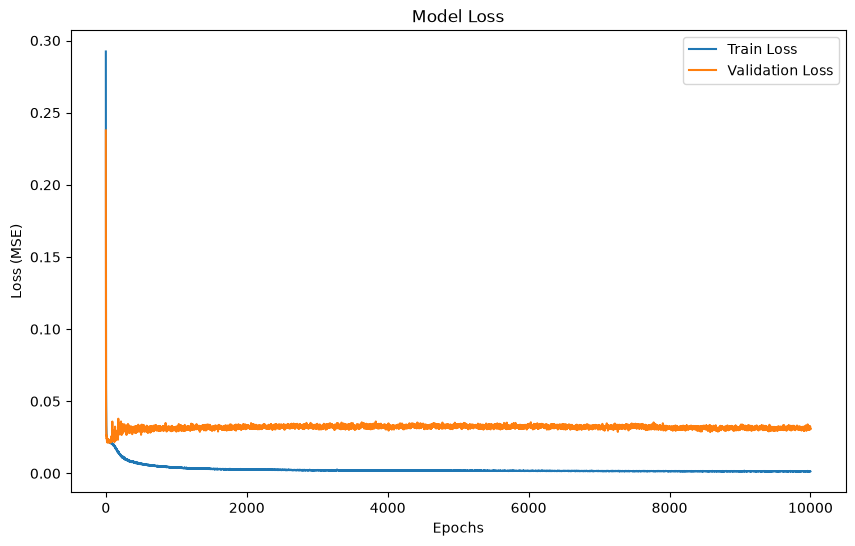

In [16]:
plt.figure(figsize=(10,6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

In [17]:
model.save("my_model.keras")